# Does using risk improve the selected 100 merchants?

This is a decision test: allow covariance risk to change **which merchants are selected**, then evaluate later revenue and downside. Earlier notebooks measured the same revenue-only portfolio.

| Policy | Selection rule |
|---|---|
| Revenue-only | Top 100 by expanding historical mean monthly gross fees |
| Raw-risk | Minimize regularized covariance-based variance of weekly fees |
| Detrended-risk | Minimize regularized covariance-based variance of fluctuations around past linear trends |

Both risk policies must retain **at least 99% of baseline expected monthly fees** and select exactly 100 eligible merchants. The 1% revenue budget is fixed before evaluation; it is a business choice, not a discovered optimum. Both covariance estimates use the same diagonal-preserving Ledoit–Wolf procedure. Here, *raw* means fees have not been detrended, not that sample covariance is used without regularization.

Primary: 26 complete weeks and eight November 2021–June 2022 origins. Sensitivity: 26 versus 52 weeks on the same five February–June origins. September 2022 provides unscored candidate lists. No additional risk factors or category constraints are introduced.

## Objective, feasibility and numerical evidence

$$\min_{z\in\{0,1\}^M}z^T\widehat\Sigma z,\qquad \sum_i z_i=100,\qquad \sum_i\mu_i z_i\geq0.99\sum_{i\in B}\mu_i.$$

Here $\mu_i$ is unchanged expected monthly gross fees, and $B$ is the revenue-only top 100. Equal inclusion means selecting a merchant; we are not allocating investment weights or inventory.

For binary selections, shrinkage variance has the form $\|Az\|^2+d^Tz$. A deterministic exchange search supplies a feasible starting portfolio. Tangent-plane mixed-integer linear problems then supply a global lower bound and improved candidates. The reported gap bounds remaining possible **variance-objective** improvement, not predictive uncertainty.

The fixed search targets a gap of at most **0.1%**. Budget-limited results remain feasible but are explicitly labelled best-found. All eligible merchants are available to the search. Feasibility, brute-force toy solutions, covariance arithmetic and reproducibility are tested. The algorithm uses the existing SciPy environment; see the [MILP documentation](https://docs.scipy.org/doc/scipy-1.16.2/reference/generated/scipy.optimize.milp.html).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here=Path.cwd()
ROOT=next(p for p in [here,*here.parents] if (p/'code/risk_aware_selection.py').exists())
sys.path.insert(0,str(ROOT/'code'))
import risk_aware_selection as experiment

selections,paired,summary=experiment.run()
OUT=experiment.OUT
plots=OUT/'plots'
plots.mkdir(exist_ok=True)
primary=paired.loc[paired.window.eq('26w') & paired.status.eq('observed') & paired.method.ne('revenue_only')]
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})

Selecting portfolios at 2021-11-30


  26w: max variance-gap bound 0.0395%


Selecting portfolios at 2021-12-31


  26w: max variance-gap bound 0.0407%


Selecting portfolios at 2022-01-31


...

  52w: max variance-gap bound 0.0000%


Selecting portfolios at 2022-09-30


  26w: max variance-gap bound 0.0434%


  52w: max variance-gap bound 0.0000%


             comparison window         method  origins  mean_expected_fee_retention_pct  mean_actual_fee_change_pct  mean_actual_fee_change_aud  worst_actual_fee_change_pct  fee_guardrail_passes  mean_actual_sd_change_pct  mean_actual_cv_change_pct  mean_downside_change_aud  mean_downside_change_reference_pct  mean_own_downside_change_aud  downside_wins  downside_ties  downside_losses  joint_successes  mean_overlap  max_optimization_gap_pct
      primary_26w_eight    26w       raw_risk        8                          99.0079                     -0.9232                 -46375.6375                      -1.0272                     7                     0.0718                     0.9935                 1791.5138                              0.4409                     -465.2703              0              2                6                0        93.500                    0.0708
      primary_26w_eight    26w detrended_risk        8                          99.0057                     -0

## Define one fair downside target

At each cutoff, freeze a **common reference**: mean weekly fees of the revenue-only baseline over the latest 26 complete weeks. Use those same reference dollars for every policy and both lookbacks.

$$D=\sqrt{\frac1H\sum_{w=1}^{H}\max(\text{common reference}-\text{portfolio fees}_w,0)^2}.$$

A lower-revenue portfolio cannot appear safer merely by lowering its own reference. We also export own-reference downside as a sensitivity, but it is not the main criterion. Sum merchant fees **before** calculating shortfalls.

- Actual revenue is gross fees from **all days** of the subsequent three complete calendar months.
- Weekly risk uses only complete Monday–Sunday weeks within that quarter: 11–13 weeks.
- A zero-downside baseline makes percentage downside changes undefined. Report dollar differences and changes relative to the common income reference.
- The 99% constraint guarantees expected-fee retention only. A separate check tests whether **realized** fee retention also reaches 99%.
- Lower estimated variance is not sufficient. The economic question is whether later downside falls with an acceptable fee trade-off.

In [2]:
display(summary.loc[summary.comparison.eq('primary_26w_eight'),
    ['method','origins','mean_expected_fee_retention_pct','mean_actual_fee_change_pct','worst_actual_fee_change_pct',
     'mean_actual_sd_change_pct','mean_actual_cv_change_pct','mean_downside_change_aud','mean_own_downside_change_aud',
     'downside_wins','downside_ties','downside_losses','fee_guardrail_passes','joint_successes']].round(3))
display(primary[['as_of','method','overlap_with_baseline','expected_fee_retention_pct','actual_fee_change_pct',
                 'actual_sd_change_pct','downside_change_aud','actual_fee_guardrail_met','downside_lower']].round(3))

,method,origins,mean_expected_fee_retention_pct,mean_actual_fee_change_pct,worst_actual_fee_change_pct,mean_actual_sd_change_pct,mean_actual_cv_change_pct,mean_downside_change_aud,mean_own_downside_change_aud,downside_wins,downside_ties,downside_losses,fee_guardrail_passes,joint_successes
0,raw_risk,8,99.008,-0.923,-1.027,0.072,0.993,1791.514,-465.270,0,2,6,7,0
1,detrended_risk,8,99.006,-0.928,-1.088,-0.809,0.100,1780.941,-464.685,0,2,6,7,0


,as_of,method,overlap_with_baseline,expected_fee_retention_pct,actual_fee_change_pct,actual_sd_change_pct,downside_change_aud,actual_fee_guardrail_met,downside_lower
1,2021-11-30,raw_risk,93,99.012,-0.816,-1.091,1476.119,True,False
2,2021-11-30,detrended_risk,94,99.000,-0.996,-1.167,2150.305,True,False
4,2021-12-31,raw_risk,94,99.005,-0.964,1.585,3085.271,True,False
5,2021-12-31,detrended_risk,93,99.003,-0.865,0.582,2645.995,True,False
7,2022-01-31,raw_risk,93,99.013,-0.885,-2.034,2340.020,True,False
8,2022-01-31,detrended_risk,93,99.007,-0.907,-2.212,2433.887,True,False
10,2022-02-28,raw_risk,93,99.008,-1.027,-0.563,3060.684,False,False
11,2022-02-28,detrended_risk,93,99.003,-0.974,-0.483,2796.634,True,False
16,2022-03-31,raw_risk,93,99.000,-0.956,5.493,2955.464,True,False
17,2022-03-31,detrended_risk,93,99.013,-0.938,5.065,2881.648,True,False


## Realized trade-offs, origin by origin

Each point compares the candidate with the revenue-only portfolio selected at the **same cutoff**. Negative SD or downside changes are improvements. Negative fee changes are income sacrificed. The dashed −1% line is the realized fee guardrail; it is not guaranteed by the optimization constraint.

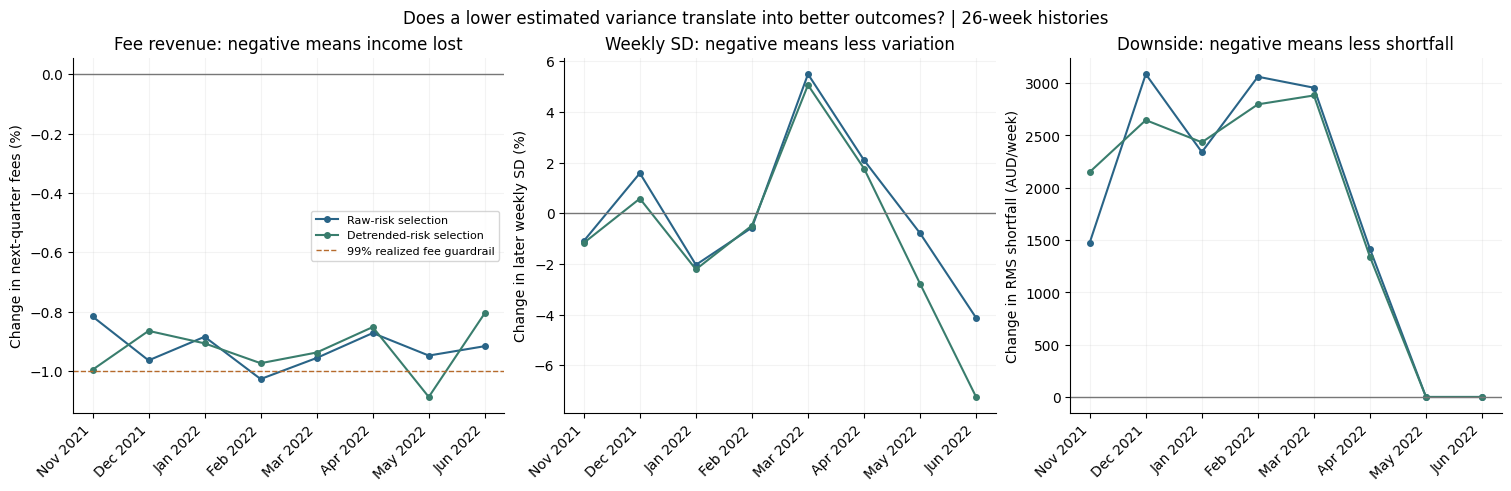

In [3]:
dates=experiment.ORIGINS
x=np.arange(len(dates))
colors={'raw_risk':'#296487','detrended_risk':'#397d6d'}
labels={'raw_risk':'Raw-risk selection','detrended_risk':'Detrended-risk selection'}
fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
for method in experiment.METHODS[1:]:
    g=primary.loc[primary.method.eq(method)].set_index('as_of').loc[dates]
    for ax,column in zip(axes,['actual_fee_change_pct','actual_sd_change_pct','downside_change_aud']):
        ax.plot(x,g[column],marker='o',markersize=4,color=colors[method],label=labels[method])
axes[0].axhline(-1,color='#b66a2c',linestyle='--',linewidth=1,label='99% realized fee guardrail')
for ax,title,ylabel in zip(axes,
        ['Fee revenue: negative means income lost','Weekly SD: negative means less variation','Downside: negative means less shortfall'],
        ['Change in next-quarter fees (%)','Change in later weekly SD (%)','Change in RMS shortfall (AUD/week)']):
    ax.axhline(0,color='#777777',linewidth=1)
    ax.set(title=title,ylabel=ylabel)
    ax.set_xticks(x,dates.strftime('%b %Y'),rotation=45,ha='right')
    ax.grid(alpha=.15)
axes[0].legend(fontsize=8)
fig.suptitle('Does a lower estimated variance translate into better outcomes? | 26-week histories')
fig.savefig(plots/'realized_tradeoffs.png',dpi=160)
plt.show()

## Common versus own-reference downside

A policy's own historical income reference can fall when it selects lower-revenue merchants. The comparison below makes that effect visible. A reduction appearing only with the lower own-reference threshold does not establish improved ability to meet the baseline income requirement.

,as_of,method,common_reference_weekly_fees,own_reference_weekly_fees,baseline_downside_common,downside_common,downside_own,downside_change_aud,downside_own_change_aud
1,2021-11-30,raw_risk,388905.86,384860.74,71206.56,72682.68,69404.82,1476.12,-1801.74
2,2021-11-30,detrended_risk,388905.86,384984.93,71206.56,73356.87,70180.16,2150.30,-1026.40
4,2021-12-31,raw_risk,419939.52,415465.48,104202.43,107287.70,102983.43,3085.27,-1219.00
5,2021-12-31,detrended_risk,419939.52,415509.91,104202.43,106848.43,102584.88,2645.99,-1617.55
7,2022-01-31,raw_risk,413071.69,408996.91,70567.58,72907.60,69126.15,2340.02,-1441.44
8,2022-01-31,detrended_risk,413071.69,409004.03,70567.58,73001.47,69224.69,2433.89,-1342.89
10,2022-02-28,raw_risk,404817.54,400762.10,32701.91,35762.59,32499.09,3060.68,-202.82
11,2022-02-28,detrended_risk,404817.54,400690.89,32701.91,35498.54,32165.69,2796.63,-536.22
16,2022-03-31,raw_risk,401718.53,398249.79,17020.80,19976.26,17922.50,2955.46,901.70
17,2022-03-31,detrended_risk,401718.53,398228.23,17020.80,19902.45,17839.68,2881.65,818.89


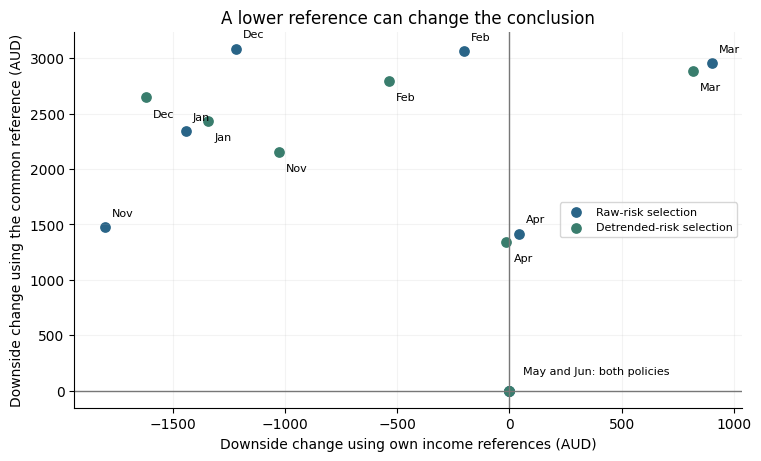

In [2]:
display(primary[['as_of','method','common_reference_weekly_fees','own_reference_weekly_fees',
                 'baseline_downside_common','downside_common','downside_own',
                 'downside_change_aud','downside_own_change_aud']].round(2))
fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
for method in experiment.METHODS[1:]:
    g=primary.loc[primary.method.eq(method)]
    ax.scatter(g.downside_own_change_aud,g.downside_change_aud,color=colors[method],label=labels[method],s=45)
    for r in g.loc[g.downside_change_aud.ne(0) | g.downside_own_change_aud.ne(0)].itertuples():
        ax.annotate(r.as_of.strftime('%b'),(r.downside_own_change_aud,r.downside_change_aud),
                    xytext=(5,8) if method=='raw_risk' else (5,-14),textcoords='offset points',fontsize=8)
ax.annotate('May and Jun: both policies',(0,0),xytext=(10,12),textcoords='offset points',fontsize=8)
ax.axhline(0,color='#777777',linewidth=1)
ax.axvline(0,color='#777777',linewidth=1)
ax.set(xlabel='Downside change using own income references (AUD)',
       ylabel='Downside change using the common reference (AUD)',
       title='A lower reference can change the conclusion')
ax.legend(fontsize=8)
ax.grid(alpha=.15)
fig.savefig(plots/'downside_reference_sensitivity.png',dpi=160)
plt.show()

## Lookback sensitivity and non-overlapping schedules

Use exactly the same five February–June origins to compare 26 and 52 weeks. The first three historical cutoffs lack 52 complete weeks. The three schedules below group the eight primary origins into non-overlapping future quarters; there are still very few economic periods, and the schedules are not independent datasets. No threshold or model is retuned after seeing these results.

In [5]:
display(summary.loc[summary.comparison.eq('sensitivity_common_five'),
    ['window','method','origins','mean_actual_fee_change_pct','mean_actual_sd_change_pct',
     'mean_downside_change_aud','downside_wins','downside_ties','downside_losses','joint_successes']].round(3))
display(pd.read_parquet(OUT/'nonoverlapping_schedules.parquet')[
    ['comparison','cutoffs','method','origins','mean_actual_fee_change_pct','mean_downside_change_aud','joint_successes']].round(3))

,window,method,origins,mean_actual_fee_change_pct,mean_actual_sd_change_pct,mean_downside_change_aud,downside_wins,downside_ties,downside_losses,joint_successes
2,26w,raw_risk,5,-0.944,0.423,1486.140,0,2,3,0
3,26w,detrended_risk,5,-0.931,-0.735,1403.469,0,2,3,0
4,52w,raw_risk,5,-0.958,-1.009,1497.791,0,2,3,0
5,52w,detrended_risk,5,-0.949,-0.201,1506.388,0,2,3,0


,comparison,cutoffs,method,origins,mean_actual_fee_change_pct,mean_downside_change_aud,joint_successes
0,schedule_0,"2021-11-30, 2022-02-28, 2022-05-31",raw_risk,3,-0.931,1512.268,0
1,schedule_0,"2021-11-30, 2022-02-28, 2022-05-31",detrended_risk,3,-1.019,1648.979,0
2,schedule_1,"2021-12-31, 2022-03-31, 2022-06-30",raw_risk,3,-0.946,2013.578,0
3,schedule_1,"2021-12-31, 2022-03-31, 2022-06-30",detrended_risk,3,-0.869,1842.547,0
4,schedule_2,"2022-01-31, 2022-04-30",raw_risk,2,-0.878,1877.286,0
5,schedule_2,"2022-01-31, 2022-04-30",detrended_risk,2,-0.880,1886.474,0


## Selected merchants, numerical gaps and validation

All 100-merchant lists, entrants/removals, category composition, expected-risk estimates and realized outcomes are saved. The latest September 2022 lists have **no future evaluation** and are not automatically adopted as the final recommendation.

Inputs are independently re-audited. Perturbing future daily transactions leaves earlier features, covariance, optimization results and selections unchanged. Every selection meets the count, eligibility and expected-fee constraints. Quarter fees and weekly totals are independently recomputed from daily records. Re-execution must reproduce the saved result digests.

In [6]:
estimates=pd.read_parquet(OUT/'unscored_estimates.parquet')
risk_estimates=estimates.loc[estimates.method.ne('revenue_only')]
display(risk_estimates[['as_of','window','method','solver_status','certified','gap_upper_fraction','overlap_with_baseline',
                        'expected_fee_retention_pct','estimated_raw_shrunk_sd','estimated_residual_shrunk_sd']].round(5))
display(selections.loc[selections.as_of.eq(pd.Timestamp('2022-09-30')) & selections.window.eq('26w')]
    .groupby('method').agg(merchants=('merchant_abn','size'),expected_monthly_fees=('expected_monthly_fees','sum'),
                         overlap=('in_revenue_baseline','sum')))
display(json.loads((OUT/'acceptance_checks.json').read_text()))

,as_of,window,method,solver_status,certified,gap_upper_fraction,overlap_with_baseline,expected_fee_retention_pct,estimated_raw_shrunk_sd,estimated_residual_shrunk_sd
1,2021-11-30,26w,raw_risk,certified_gap,True,0.00014,93,99.01151,41191.27176,31897.47721
2,2021-11-30,26w,detrended_risk,certified_gap,True,0.00039,94,99.00005,41497.08630,31705.95153
4,2021-12-31,26w,raw_risk,certified_gap,True,0.00020,94,99.00545,68689.18212,39295.83407
5,2021-12-31,26w,detrended_risk,certified_gap,True,0.00041,93,99.00270,68917.94824,38964.24237
7,2022-01-31,26w,raw_risk,certified_gap,True,0.00025,93,99.01269,77549.07315,78936.30088
8,2022-01-31,26w,detrended_risk,certified_gap,True,0.00041,93,99.00711,77562.55600,78932.36546
10,2022-02-28,26w,raw_risk,certified_gap,True,0.00061,93,99.00795,83835.45611,82513.91979
11,2022-02-28,26w,detrended_risk,certified_gap,True,0.00090,93,99.00255,83903.85958,82497.68047
13,2022-02-28,52w,raw_risk,certified_gap,True,0.00042,93,99.01316,69253.85660,64270.78207
14,2022-02-28,52w,detrended_risk,certified_gap,True,0.00000,93,99.00382,69285.11875,64213.40758


,merchants,expected_monthly_fees,overlap
method,,,
detrended_risk,100,1.649772e+06,97
raw_risk,100,1.649806e+06,95
revenue_only,100,1.666400e+06,100


{'source_signatures_checksum_calendar_reconciliation': True,
 'unique_exactly_100_eligible': True,
 'expected_fee_floor': True,
 'same_downside_reference_across_all_methods_windows': True,
 'numerical_variance_reconciliation': True,
 'baseline_reproductions': 9,
 'future_daily_perturbations': 13,
 'independent_daily_quarter_and_weekly_fee_checks': 39,
 'frozen_before_outcomes': True,
 'september_unscored': True,
 'reproducible_rerun': True,
 'digests': {'estimates': 'c97f6ff5286ee688ef90ff1b9a20f7e1fc01b05e8b6e7f52bb853c34811d2e06',
  'selections': '30ffb20b639c922af932af70c54d544b347ce219ceccf4e2b0715729c14fb43c',
  'outcomes': '9bfcd23190783e76bdbf2b2c2f748c3a4f65c4666b776c6ed025c9f525488ccd',
  'summary': '1b30c1997805d4daebf9c6616f0316837648e334ab73b07359c9972395ec44cd',
  'solver_log': 'dd1021e311ad823ef355bd89cd9936ff57a78f978ec572a8c9b867049945fb62'}}

## Interpretation and reproduction

The findings report states whether lower estimated covariance translated into lower observed downside and whether realized fees stayed above the guardrail. No policy is promoted solely because its in-sample risk is lower.

The data are synthetic and the historical outcomes have already been examined. Assume stable take rates/categories and that hypothetical onboarding does not change observed merchant sales or cause substitution across merchants. Gross fees are not net profit, credit losses or settlement cash flow. These overlapping short tests support project-level comparisons, not causal or statistically definitive claims.

**Run:** `python code/risk_aware_selection.py`  
**Test:** `python -m pytest -p no:capture code/tests/test_risk_aware_selection.py -q`

Use existing pinned `requirements-forecast.txt`. Outputs stay in ignored `tables/analysis/risk_aware_selection/` as uncompressed Parquet and CSV. Previous experiments are preserved.

In [7]:
display(Markdown((OUT/'findings.md').read_text(encoding='utf-8')))

# Does covariance risk improve merchant selection?

The experiment selects exactly 100 eligible merchants and retains at least 99% of the revenue-only portfolio's expected monthly gross fees. Expected return remains the expanding historical complete-month mean. The revenue-only selection, raw-fee covariance selection and detrended covariance selection all use the same candidate pool and dates. Both risk methods use the existing variance-preserving Ledoit-Wolf shrinkage; 'raw' means fees are not detrended, not that covariance is unregularized.

Primary: eight November 2021-June 2022 cutoffs with 26 historical weeks. Sensitivity: 26 vs 52 weeks on the same five February-June dates. September 2022 selections are unscored snapshots. Settings and all selections were frozen before attaching outcomes. There is no new untouched holdout.

## Primary results

All changes below are candidate minus revenue-only baseline. Negative downside and SD changes are improvements; negative fee changes are revenue sacrificed. Means give each origin equal weight.

| Risk objective | Fee change | SD change | Downside change (A$/week RMS) | Downside wins/ties/losses | Realized 99% fee guardrail | Both improve downside and pass guardrail |
|---|---:|---:|---:|---:|---:|---:|
| raw_risk | -0.923% | +0.072% | +1,791.51 | 0/2/6 | 7/8 | 0/8 |
| detrended_risk | -0.928% | -0.809% | +1,780.94 | 0/2/6 | 7/8 | 0/8 |

**Decision: retain the revenue-only top 100.** Neither tested risk-aware policy improved realized downside at any primary origin, while both gave up revenue. The two zero-downside ties do not count as improvements. A lower predicted variance did not deliver the intended economic benefit.

Using each portfolio's own income reference gives an apparently better average downside result here, but that reference falls when lower-income merchants are selected. Against the common baseline income requirement, the conclusion reverses. The common-reference comparison is the predeclared test.

The 99% selection constraint is on EXPECTED fees. Actual next-quarter fees can violate it; these failures are reported rather than excluded. Lower estimated variance is not the same as lower realized downside. Results are for this fixed 1% revenue budget, not an optimized business trade-off.

## Every historical primary comparison

| Cutoff | Method | Expected retention | Actual fee change | Actual SD change | Downside change (A$) | Overlap |
|---|---|---:|---:|---:|---:|---:|
| 2021-11-30 | raw_risk | 99.0115% | -0.816% | -1.091% | +1,476.12 | 93/100 |
| 2021-11-30 | detrended_risk | 99.0001% | -0.996% | -1.167% | +2,150.30 | 94/100 |
| 2021-12-31 | raw_risk | 99.0054% | -0.964% | +1.585% | +3,085.27 | 94/100 |
| 2021-12-31 | detrended_risk | 99.0027% | -0.865% | +0.582% | +2,645.99 | 93/100 |
| 2022-01-31 | raw_risk | 99.0127% | -0.885% | -2.034% | +2,340.02 | 93/100 |
| 2022-01-31 | detrended_risk | 99.0071% | -0.907% | -2.212% | +2,433.89 | 93/100 |
| 2022-02-28 | raw_risk | 99.0079% | -1.027% | -0.563% | +3,060.68 | 93/100 |
| 2022-02-28 | detrended_risk | 99.0025% | -0.974% | -0.483% | +2,796.63 | 93/100 |
| 2022-03-31 | raw_risk | 99.0002% | -0.956% | +5.493% | +2,955.46 | 93/100 |
| 2022-03-31 | detrended_risk | 99.0129% | -0.938% | +5.065% | +2,881.65 | 93/100 |
| 2022-04-30 | raw_risk | 99.0042% | -0.872% | +2.096% | +1,414.55 | 94/100 |
| 2022-04-30 | detrended_risk | 99.0100% | -0.852% | +1.769% | +1,339.06 | 93/100 |
| 2022-05-31 | raw_risk | 99.0157% | -0.948% | -0.788% | +0.00 | 93/100 |
| 2022-05-31 | detrended_risk | 99.0057% | -1.088% | -2.780% | +0.00 | 93/100 |
| 2022-06-30 | raw_risk | 99.0056% | -0.916% | -4.126% | +0.00 | 95/100 |
| 2022-06-30 | detrended_risk | 99.0045% | -0.805% | -7.249% | +0.00 | 97/100 |

## Fair downside evaluation

At each cutoff, fix one common reference: the revenue-only baseline's mean gross weekly fees over the latest 26 complete weeks. Every policy, including the 52-week sensitivity, is evaluated against that SAME dollar reference. Downside is sqrt(mean(max(reference - total weekly fees, 0)^2)); sum merchants before applying the shortfall. A policy cannot look safer simply by lowering its own reference. A separate own-reference downside sensitivity is exported and must not replace this main test.

Full-quarter fee revenue includes every day in the next three complete calendar months. Weekly risk uses only complete Monday-Sunday weeks entirely inside that quarter (11-13 observations). Risk percentages are not annualized. When baseline downside is zero, percentage downside change is undefined; report dollar differences and changes divided by the common reference instead. Volatility/mean is also reported to check whether an apparent SD reduction merely reflects lower income.

## Numerical search

Minimize z' Sigma z subject to sum(z)=100, z binary, and expected fees >=99% of baseline. No candidate shortlist, fraud penalty, customer-concentration rule, trend filter or category constraint is added. For binary z, shrinkage variance can be written ||Bz||^2 + d'z. A deterministic improving exchange search initializes the incumbent, then tangent-plane mixed-integer linear problems give a valid global lower bound. The recorded gap bounds the remaining possible variance improvement; it does not measure statistical uncertainty. Numerical solver inputs are sorted by numeric ABN. Baseline and display ranks break expected-fee ties by ABN. Exact equal-objective incumbents prefer the lower sorted ABN tuple.

Search settings: {'max_cuts': 30, 'node_limit': 200, 'relative_gap': 0.001, 'max_swaps': 200}. Each MILP uses a fixed node budget, not a machine-dependent time budget. All achieved gaps and solver logs are exported; budget-limited results are called best-found, not exact optima. See [SciPy's MILP documentation](https://docs.scipy.org/doc/scipy-1.16.2/reference/generated/scipy.optimize.milp.html).

30/30 risk portfolios meet the predeclared 0.1% variance-gap tolerance; the largest recorded bound is 0.0993%.

## Interpretation

For raw_risk, average realized downside is higher or unchanged; downside improves in 0/8 tests and improves while retaining 99% of realized fees in 0/8. The worst fee change is -1.027%. These results describe the trade-off; they do not establish a universally better policy.
For detrended_risk, average realized downside is higher or unchanged; downside improves in 0/8 tests and improves while retaining 99% of realized fees in 0/8. The worst fee change is -1.088%. These results describe the trade-off; they do not establish a universally better policy.

Use the same-origin 52-week sensitivity and the three non-overlapping schedules to inspect stability. The existing revenue-only baseline is preserved; no method is silently promoted after seeing these already-used outcomes. Detrending can hide smooth decline, while raw variance can penalize growth. The economic test, not the in-sample risk objective, determines whether either helps here.

This conclusion concerns these covariance estimates, this data and the fixed 1% expected-fee budget. It does not show that diversification can never help, or address fraud and customer-concentration risks.

Assume take rates/categories were historically known and stable, and onboarding a merchant would not change its historical sales or the sales of other merchants. Gross fees exclude credit/fraud losses, funding and operating expenses, and settlement timing. Synthetic history, few economic periods and overlapping quarters limit generalization. No statistical-significance or causal claim is made.

## Reproduce

Run `python code/risk_aware_selection.py`; tests: `python -m pytest -p no:capture code/tests/test_risk_aware_selection.py -q`. The explanatory notebook is code/07_risk_aware_selection.ipynb. Use existing pinned requirements-forecast.txt; no additional optimizer package, GPU or API is required. Outputs are uncompressed Parquet and CSV in ignored tables/analysis/risk_aware_selection/. Latest 26-week candidate lists are explicitly labelled by method; they are not validated September recommendations.
